In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import ConfusionMatrixDisplay
from GTZANClassifierAnalysis import GTZANClassifierAnalysis

In [ ]:
gca_gb = GTZANClassifierAnalysis().load_data()
gca_adj_gb = GTZANClassifierAnalysis(sub_folder='/adj_params').load_data()
gca_adj_no_gb = GTZANClassifierAnalysis(sub_folder='').load_data()
gca_no_gb = GTZANClassifierAnalysis(sub_folder='/og_params_no_gb').load_data()

Loading TRAIN split from: train_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\train_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading TEST split from: test_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\test_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading VAL split from: valid_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\valid_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Train size: 463 | Val size: 203 | Test size: 300
-> Data splits successfully reconstructed for '30s_full_rng42'.
Models successfully loaded from './trained_models/og_params/30s_full_rng42.pkl'.

Loading TRAIN split from: train_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\train_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading TEST split from: test_filtered_30s_features.csv
Datase

Top 4 Models Across All Configurations:
1. [30s_mfcc_rng605] Random Forest | F1: 0.3808 | Acc: 0.4225
2. [30s_full_rng42] KNN | F1: 0.3910 | Acc: 0.4208
3. [30s_full_rng351] KNN | F1: 0.3910 | Acc: 0.4208
4. [30s_full_rng605] KNN | F1: 0.3910 | Acc: 0.4208


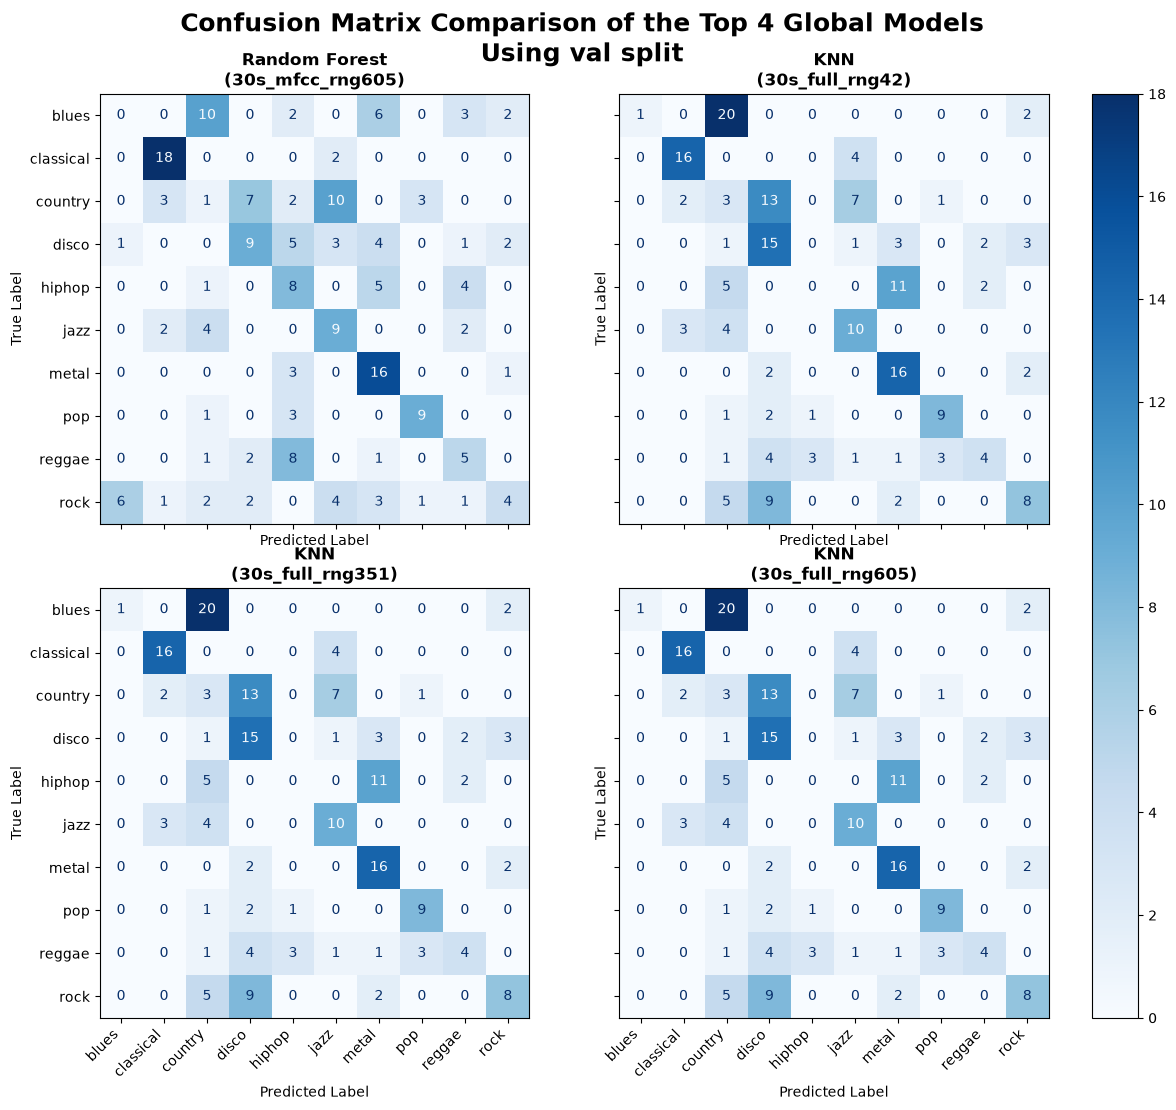

Top 4 Models Across All Configurations:
1. [30s_full_rng605] Tuned Ensemble (SVM + RF + GB) | F1: 0.4086 | Acc: 0.4350
2. [30s_full_rng605] Random Forest | F1: 0.3944 | Acc: 0.4209
3. [30s_full_rng351] Tuned Ensemble (SVM + RF + GB) | F1: 0.3930 | Acc: 0.4196
4. [30s_full_rng351] Random Forest | F1: 0.3931 | Acc: 0.4179


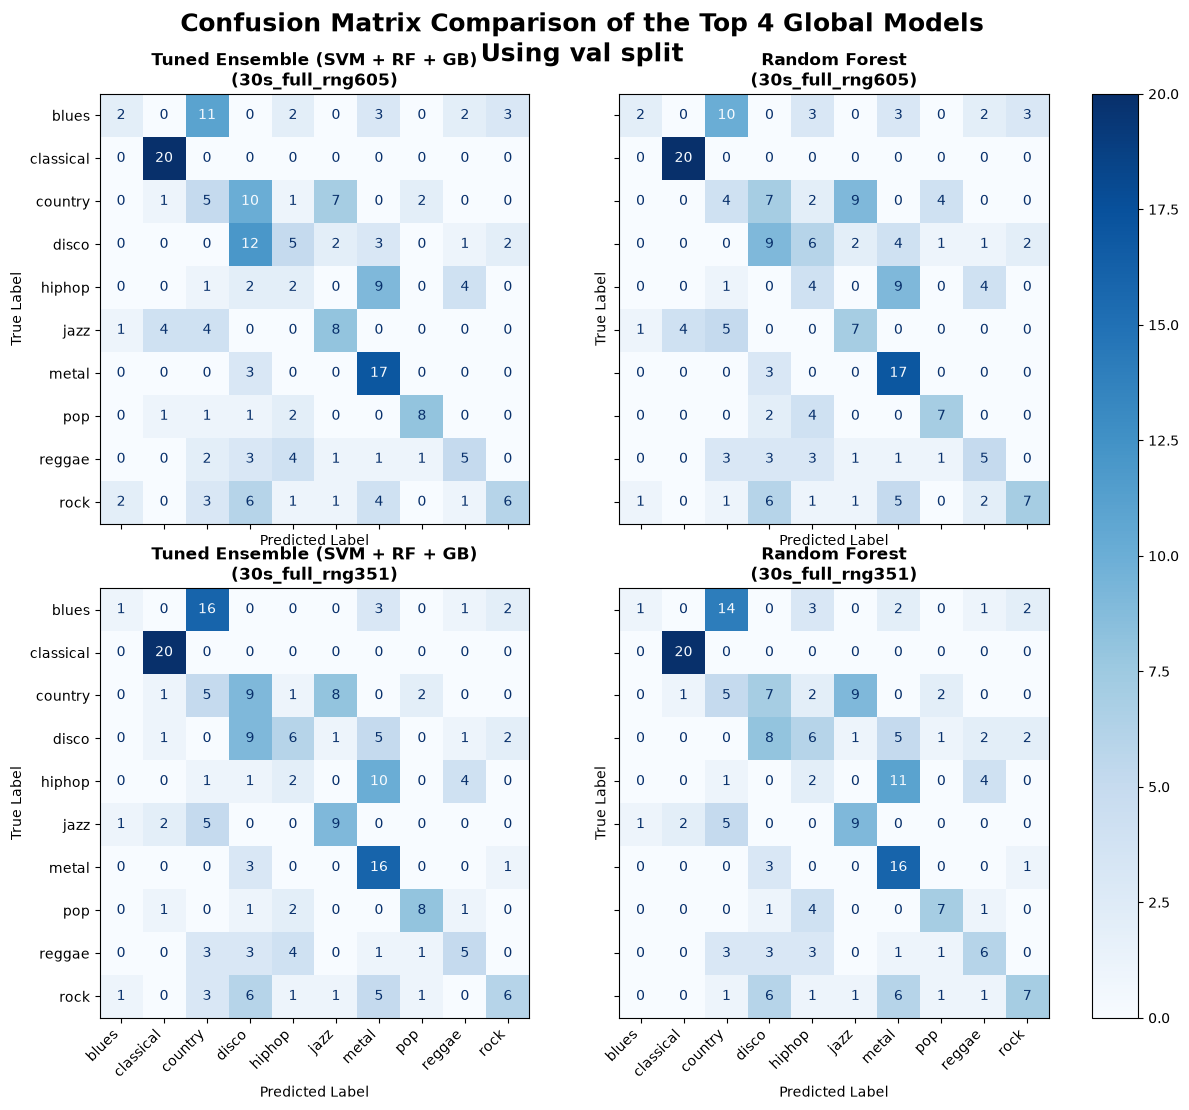

Top 4 Models Across All Configurations:
1. [30s_mfcc_rng605] Random Forest | F1: 0.3808 | Acc: 0.4225
2. [30s_full_rng42] KNN | F1: 0.3910 | Acc: 0.4208
3. [30s_full_rng351] KNN | F1: 0.3910 | Acc: 0.4208
4. [30s_full_rng605] KNN | F1: 0.3910 | Acc: 0.4208


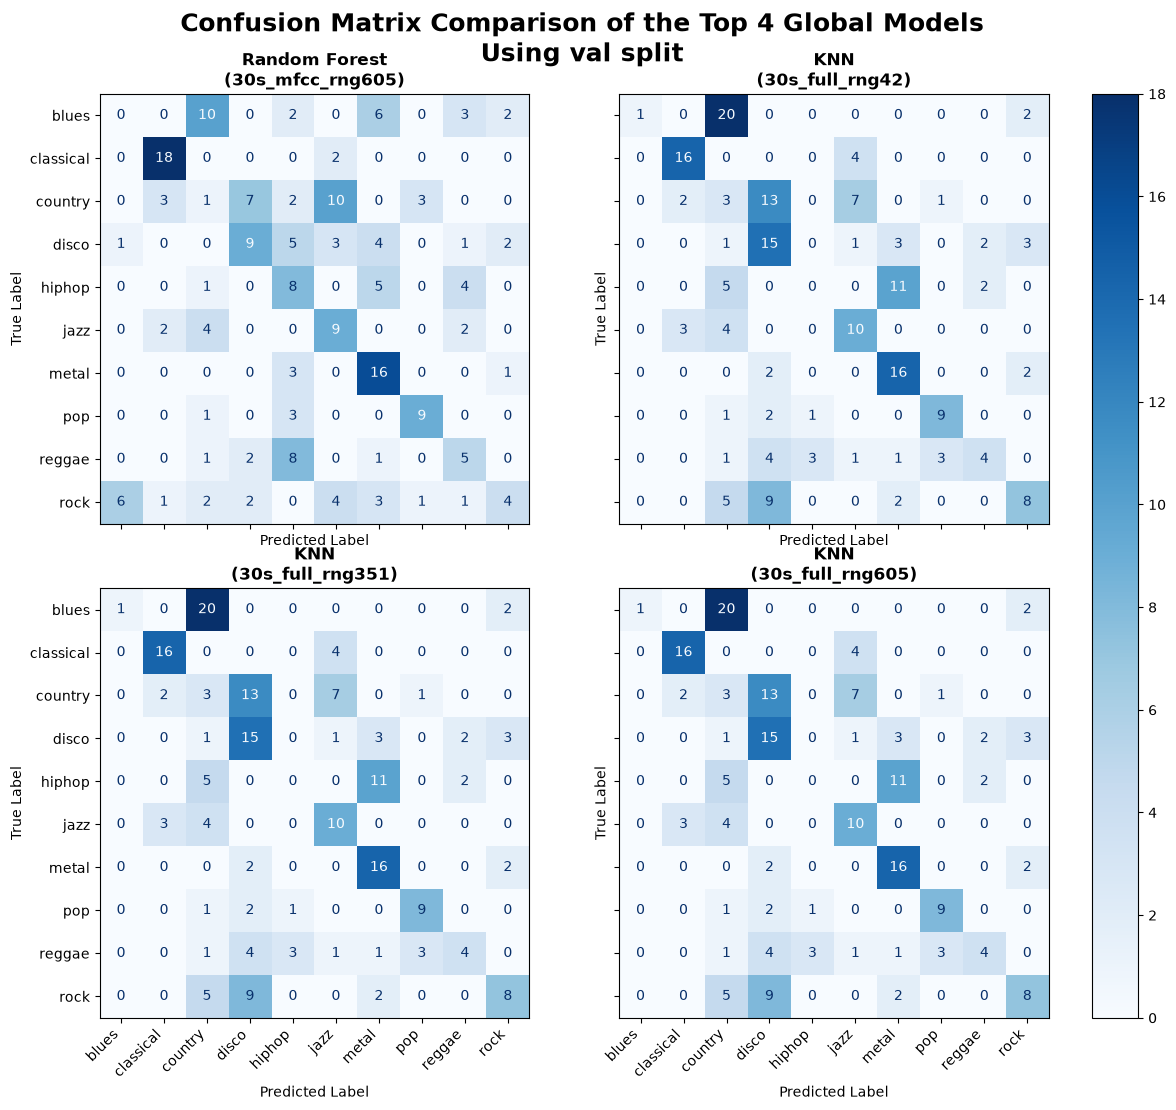

Top 4 Models Across All Configurations:
1. [30s_full_rng605] Random Forest | F1: 0.3944 | Acc: 0.4209
2. [30s_full_rng351] Random Forest | F1: 0.3931 | Acc: 0.4179
3. [30s_full_rng42] KNN + Linear SVM (Ensemble) | F1: 0.3919 | Acc: 0.4140
4. [30s_full_rng351] KNN + Linear SVM (Ensemble) | F1: 0.3919 | Acc: 0.4140


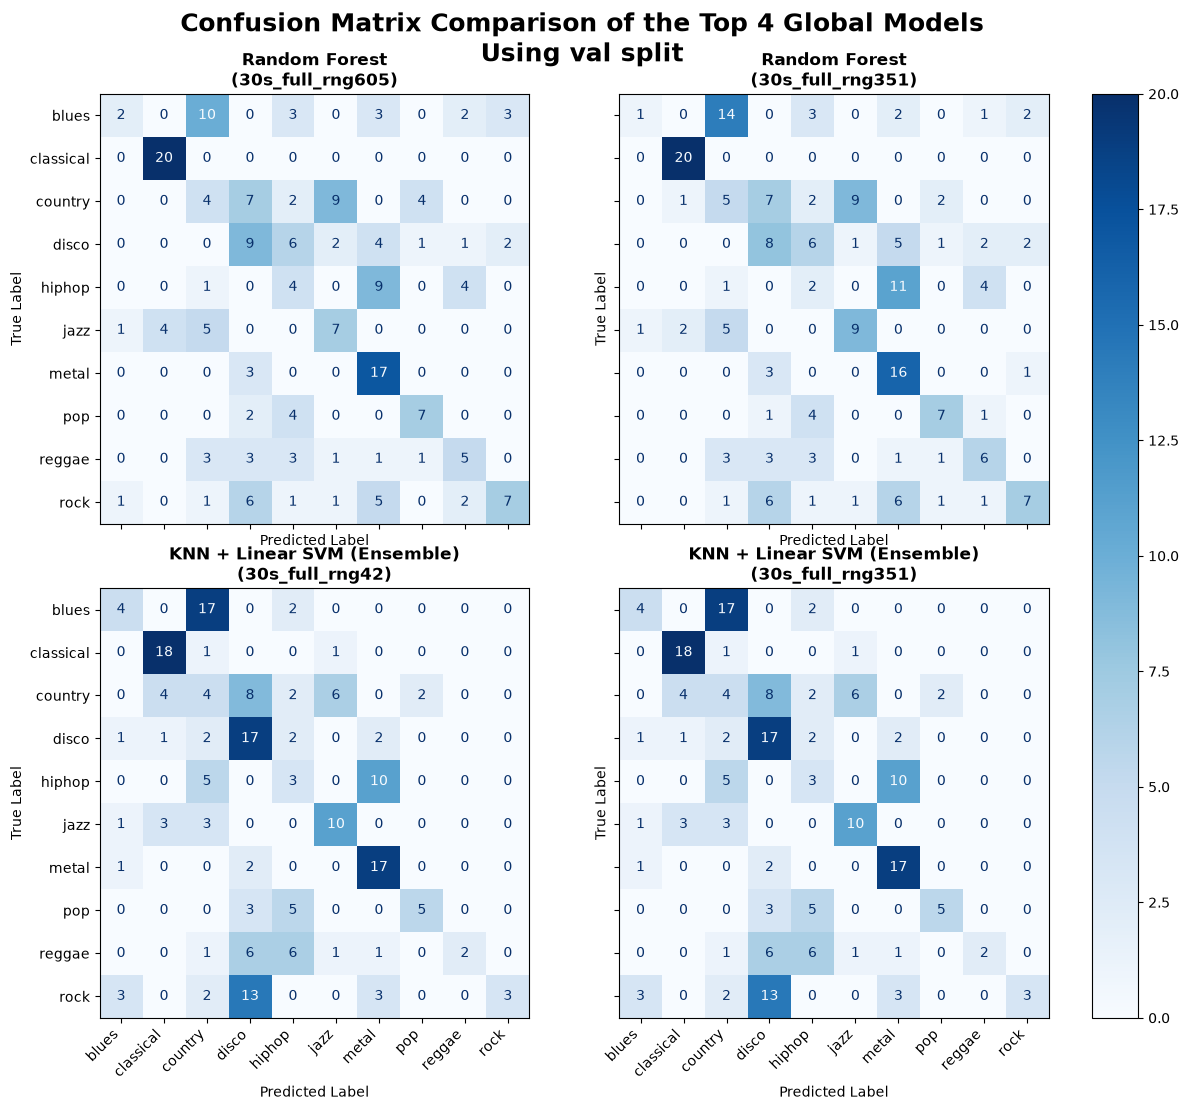

In [3]:
top4 , *_ = gca_gb.top4_configs()
top4_adj , *_ = gca_adj_gb.top4_configs()
top4_no_gb , *_ = gca_no_gb.top4_configs()
top4_adj_no_gb , *_ = gca_adj_no_gb.top4_configs()

In [59]:
def analyse_gca(gca):
    data_split = gca.dataset_split
    df_ens_val = gca.compare_ensembles_val(split=data_split)
    df_ens_summary = gca.summarize_ensemble_comparison(df_ens_val)

    print(f"=== Per-Run {data_split} Comparison (Baseline vs Candidate Ensemble) ===")
    print(df_ens_val.round(4))

    print(f"\n=== Mean {data_split} Comparison Across Seeds ===")
    print(df_ens_summary.round(4))

    # Per-genre breakdown & validation confusion matrices for a chosen seed/config
    df_genre, cm_base, cm_cand = gca.compare_per_class_val(
        config_name="30s_full_rng605",
        split=data_split,
    )
    print(f"\n=== Per-Genre {data_split} F1 & Recall Lift ===")
    print(df_genre.round(4))

In [60]:
analyse_gca(gca_gb)

=== Per-Run val Comparison (Baseline vs Candidate Ensemble) ===
  Dataset Features  rng    Configuration  Base Rank  Cand Rank  Base Acc  \
0     30s     full   42   30s_full_rng42          2          5    0.4138   
1     30s     full  351  30s_full_rng351          2          4    0.4138   
2     30s     full  605  30s_full_rng605          2          3    0.4138   
3     30s     mfcc   42   30s_mfcc_rng42          4          1    0.3793   
4     30s     mfcc  351  30s_mfcc_rng351          2          5    0.3793   
5     30s     mfcc  605  30s_mfcc_rng605          4          3    0.3793   

   Cand Acc  Delta Acc  Base Bal Acc  Cand Bal Acc  Delta Bal Acc  \
0    0.3842    -0.0296        0.4190        0.3970        -0.0220   
1    0.3842    -0.0296        0.4190        0.4007        -0.0183   
2    0.4039    -0.0099        0.4190        0.4188        -0.0002   
3    0.3842     0.0049        0.3918        0.4097         0.0179   
4    0.3645    -0.0148        0.3918        0.3762        

In [6]:
analyse_gca(gca_adj_gb)

=== Per-Run Validation Comparison (Baseline vs Candidate Ensemble) ===
  Dataset Features  rng    Configuration  Base Rank  Cand Rank  Base Acc  \
0     30s     full   42   30s_full_rng42          1          4    0.4089   
1     30s     full  351  30s_full_rng351          3          1    0.4089   
2     30s     full  605  30s_full_rng605          3          1    0.4089   
3     30s     mfcc   42   30s_mfcc_rng42          2          3    0.3793   
4     30s     mfcc  351  30s_mfcc_rng351          2          6    0.3793   
5     30s     mfcc  605  30s_mfcc_rng605          3          4    0.3793   

   Cand Acc  Delta Acc  Base Bal Acc  Cand Bal Acc  Delta Bal Acc  \
0    0.3842    -0.0246        0.4140        0.4047        -0.0093   
1    0.3990    -0.0099        0.4140        0.4196         0.0056   
2    0.4187     0.0099        0.4140        0.4350         0.0211   
3    0.3645    -0.0148        0.3918        0.3885        -0.0032   
4    0.3448    -0.0345        0.3918        0.3663 

In [13]:
best_models = gca_gb.get_best_baseline_candidate_models()

In [ ]:
best['full base']['model_dict']

{'config_name': '30s_full_rng351',
 'dataset': '30s',
 'features': 'full',
 'rng': '351',
 'model_name': 'KNN + Linear SVM (Ensemble)',
 'score_tuple': (0.4189923601547642, 0.39824943872325747, 0.41379310344827586),
 'model_dict': {'model': VotingClassifier(estimators=[('knn',
                                Pipeline(steps=[('standardscaler',
                                                 StandardScaler()),
                                                ('kneighborsclassifier',
                                                 KNeighborsClassifier(algorithm='brute',
                                                                      n_neighbors=12))])),
                               ('svm',
                                Pipeline(steps=[('standardscaler',
                                                 StandardScaler()),
                                                ('linearsvc',
                                                 LinearSVC(max_iter=10000,
                       

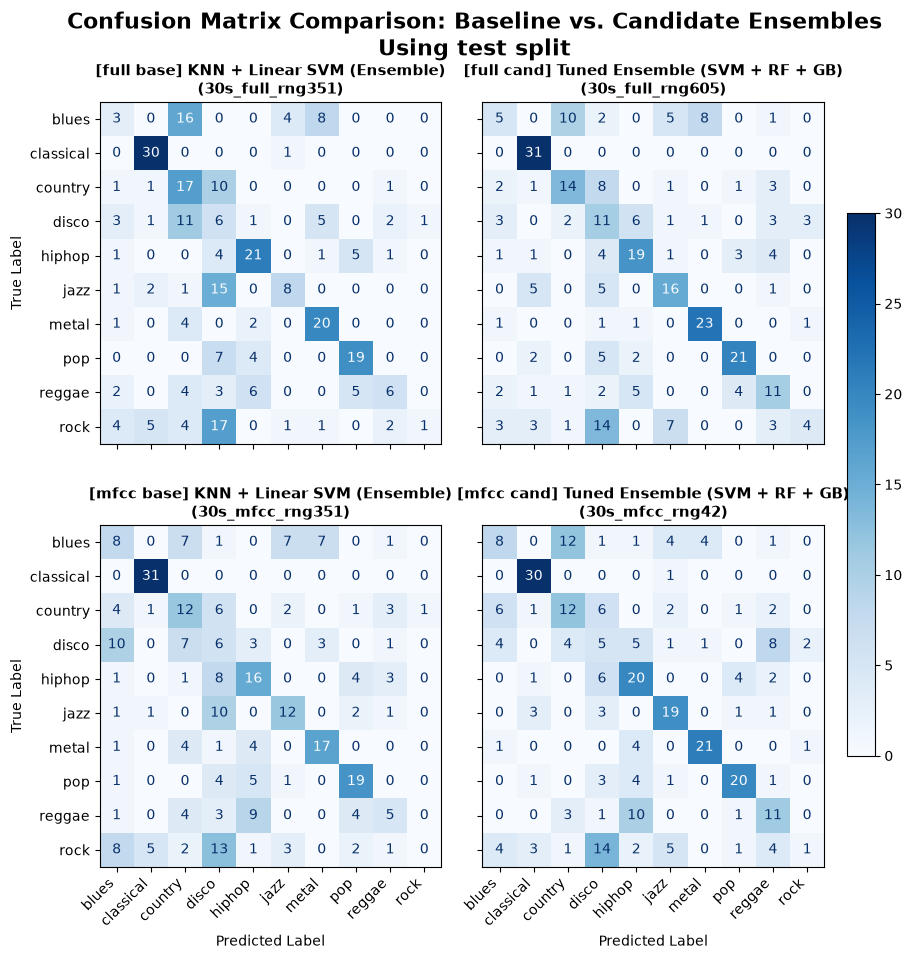

In [14]:
slot_order = ["full base", "full cand", "mfcc base", "mfcc cand"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(10,10),
    sharex=True,
    sharey=True,
    gridspec_kw={"hspace": 0.22, "wspace": 0.12},
)
axes_flat = axes.ravel()
im1 = None

for idx, slot in enumerate(slot_order):
    ax = axes_flat[idx]
    info = best_models.get(slot)

    if not info or info.get("model_dict") is None:
        ax.set_visible(False)
        continue

    c_name = info["config_name"]
    m_name = info["model_name"]
    model_dict = info["model_dict"]
    clf = gca_gb.classifers[c_name]

    cm = model_dict["metrics"]['test']["confusion_matrix"]
    labels = getattr(clf, "labels", None)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels,
    )
    disp.plot(
        ax=ax,
        cmap=plt.cm.Blues,
        colorbar=False,
        xticks_rotation=45,
    )

    # Ensure tick labels remain visible across shared axes when rotated
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    # Keep outer axis labels clean
    ax.set_xlabel("Predicted Label" if idx >= 2 else "", fontsize=10)
    ax.set_ylabel("True Label" if idx % 2 == 0 else "", fontsize=10)
    ax.set_title(f"[{slot}] {m_name}\n({c_name})", fontsize=11, fontweight="bold")

    if im1 is None:
        im1 = disp.im_

if im1 is not None:
    fig.colorbar(
        im1,
        ax=axes_flat.tolist(),
        fraction=0.035,
        pad=0.03,
    )

fig.suptitle(
    f"Confusion Matrix Comparison: Baseline vs. Candidate Ensembles\nUsing test split",
    fontsize=16,
    y=0.97,
    fontweight="bold",
)

plt.show()

In [20]:
def compare_best_models_compute(
    best_models: dict,
    split: str = "val",
    time_key: str = "training_time_seconds",
) -> pd.DataFrame:
    """
    Compares training time and serialized model memory usage across the 4 best
    models in `best_models` ('full base', 'full cand', 'mfcc base', 'mfcc cand').
    """
    slot_order = ["full base", "full cand", "mfcc base", "mfcc cand"]
    rows = []

    for slot in slot_order:
        entry = best_models.get(slot)
        if not entry:
            continue

        model_dict = entry.get("model_dict", entry)
        m_train = model_dict.get("training metrics", {})
        m_split = model_dict.get("metrics", {}).get(split, {})
        estimator = model_dict.get("model")

        train_time_s = m_train.get(time_key, float("nan"))
        memory_bytes = len(pickle.dumps(estimator)) if estimator is not None else float("nan")
        memory_kb = memory_bytes / 1024 if pd.notna(memory_bytes) else float("nan")
        memory_mb = memory_kb / 1024 if pd.notna(memory_kb) else float("nan")

        rows.append({
            "Slot": slot,
            "Config": entry.get("config_name", ""),
            "Model": entry.get("model_name", ""),
            f"{split.capitalize()} Bal Acc": m_split.get("bal_accuracy", float("nan")),
            f"{split.capitalize()} F1": m_split.get("f1_score", float("nan")),
            "Train Time (s)": train_time_s,
            "Memory (KB)": memory_kb,
            "Memory (MB)": memory_mb,
        })

    df = pd.DataFrame(rows)
    if df.empty:
        return df

    # Relative overhead compared to 'full base' (and 'mfcc base' for cand slots)
    base_time = df.loc[df["Slot"] == "full base", "Train Time (s)"].squeeze()
    base_mem = df.loc[df["Slot"] == "full base", "Memory (KB)"].squeeze()

    if pd.notna(base_time) and base_time > 0:
        df["Time vs Full Base (x)"] = df["Train Time (s)"] / base_time
    if pd.notna(base_mem) and base_mem > 0:
        df["Mem vs Full Base (x)"] = df["Memory (KB)"] / base_mem

    return df

In [40]:
cmp_best = compare_best_models_compute(best_models,split='test')

In [42]:
def evaluate_best_models_on_test(
    best_models: dict,
    test_split: str = "test",
    val_split: str = "val",
) -> pd.DataFrame:
    """
    Takes `best_models` (selected on validation) and outputs a summary table of
    their `test_split` metrics alongside `val_split` metrics for reference.
    """
    slot_order = ["full base", "full cand", "mfcc base", "mfcc cand"]
    rows = []

    for slot in slot_order:
        entry = best_models.get(slot)
        if not entry:
            continue

        model_dict = entry.get("model_dict", entry)
        metrics = model_dict.get("metrics", {})
        m_test = metrics.get(test_split, {})
        m_val = metrics.get(val_split, {})

        rows.append({
            "Slot": slot,
            "Config": entry.get("config_name", ""),
            "Model": entry.get("model_name", ""),
            "Test Acc": m_test.get("accuracy", float("nan")),
            "Test Bal Acc": m_test.get("bal_accuracy", float("nan")),
            "Test Macro F1": m_test.get("f1_score", float("nan")),
            "Test Precision": m_test.get("precision", float("nan")),
            "Test Recall": m_test.get("recall", float("nan")),
            "Val Bal Acc": m_val.get("bal_accuracy", float("nan")),
            "Val Macro F1": m_val.get("f1_score", float("nan")),
        })

    return pd.DataFrame(rows)

In [43]:
evaluate_best_models_on_test(best_models)

,Slot,Config,Model,Test Acc,Test Bal Acc,Test Macro F1,Test Precision,Test Recall,Val Bal Acc,Val Macro F1
0,full base,30s_full_rng351,KNN + Linear SVM (Ensemble),0.436667,0.439726,0.418222,0.476743,0.439726,0.418992,0.398249
1,full cand,30s_full_rng605,Tuned Ensemble (SVM + RF + GB),0.516667,0.525219,0.501418,0.516805,0.525219,0.418773,0.396520
2,mfcc base,30s_mfcc_rng351,KNN + Linear SVM (Ensemble),0.420000,0.424263,0.404420,0.394184,0.424263,0.391784,0.362442
3,mfcc cand,30s_mfcc_rng42,Tuned Ensemble (SVM + RF + GB),0.490000,0.499833,0.475137,0.476945,0.499833,0.409687,0.379751


In [44]:
gca_test = GTZANClassifierAnalysis(dataset_split='test').load_data()

Loading TRAIN split from: train_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\train_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading TEST split from: test_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\test_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading VAL split from: valid_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\valid_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Train size: 463 | Val size: 203 | Test size: 300
-> Data splits successfully reconstructed for '30s_full_rng42'.
Models successfully loaded from './trained_models/og_params/30s_full_rng42.pkl'.

Loading TRAIN split from: train_filtered_30s_features.csv
Dataset 'GTZAN\Data_filtered\30s_split\train_filtered_30s_features.csv' has 0 missing entries.
Feature Subset: Full feature set.
Loading TEST split from: test_filtered_30s_features.csv
Datase

In [61]:
analyse_gca(gca_test)

=== Per-Run test Comparison (Baseline vs Candidate Ensemble) ===
  Dataset Features  rng    Configuration  Base Rank  Cand Rank  Base Acc  \
0     30s     full   42   30s_full_rng42          6          2    0.4367   
1     30s     full  351  30s_full_rng351          6          2    0.4367   
2     30s     full  605  30s_full_rng605          6          1    0.4367   
3     30s     mfcc   42   30s_mfcc_rng42          6          2    0.4200   
4     30s     mfcc  351  30s_mfcc_rng351          6          1    0.4200   
5     30s     mfcc  605  30s_mfcc_rng605          6          2    0.4200   

   Cand Acc  Delta Acc  Base Bal Acc  Cand Bal Acc  Delta Bal Acc  \
0    0.5100     0.0733        0.4397        0.5178         0.0781   
1    0.5067     0.0700        0.4397        0.5150         0.0752   
2    0.5167     0.0800        0.4397        0.5252         0.0855   
3    0.4900     0.0700        0.4243        0.4998         0.0756   
4    0.5100     0.0900        0.4243        0.5204       